# Phase 1: DAVIS and KIBA data

Rebuild observed pairs from the DeepDTA text matrices, construct supported DAVIS
mutants, collapse identical molecular content, tokenise and split. All functions
are defined here; assertions are the executable checks. No network or pickle is
used. Paths work from `Project/` or `Project/notebooks/`.

The sibling SC4020 EDA supplies the loading/aggregation style and optional
ID-keyed score cross-checks. DAVIS labels are pKd (higher is stronger), with the
10,000 nM screening limit retained as censored. KIBA labels stay on their own
scale; later phases must not treat these two scales as interchangeable.

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "data/raw").is_dir()
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"
FIGURES = ROOT / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
GZIP = {"method": "gzip", "mtime": 0}
SEED = 4001
PARTITIONS = ("train", "val", "test")
sns.set_theme()

## 1. Load and clean

JSON insertion order defines the matrix axes. Missing cells are omitted;
non-finite scores and non-positive DAVIS Kd values are removed and counted.
The optional SC4020 CSVs are read only for an ID-aligned cross-check here.

In [2]:
def read_matrix(path):
    """Read a whitespace-separated affinity matrix.

    Args:
        path: Text matrix path; nan/na denote unobserved cells.

    Returns:
        A float array with drugs as rows and targets as columns.
    """
    rows = []
    with path.open() as fh:
        for line in fh:
            if line.strip():
                rows.append([np.nan if t.lower() in ("nan", "na") else float(t)
                             for t in line.split()])
    return np.array(rows, dtype=float)


def load(name, matrix_file):
    """Load a benchmark while preserving identifier order.

    Args:
        name: Lowercase dataset name.
        matrix_file: Matrix filename within its raw directory.

    Returns:
        A dict containing name, matrix, ligands and targets.

    Raises:
        AssertionError: If matrix shape disagrees with the identifier maps.
    """
    folder = RAW / name
    ligands = json.loads((folder / "ligands_can.txt").read_text())
    targets = json.loads((folder / "proteins.txt").read_text())
    matrix = read_matrix(folder / matrix_file)
    assert matrix.shape == (len(ligands), len(targets))
    return dict(name=name, matrix=matrix, ligands=ligands, targets=targets)


def to_long(ds):
    """Flatten observed cells and put labels on a higher-is-stronger scale.

    Args:
        ds: Loaded benchmark dict.

    Returns:
        ID-keyed DataFrame with raw, score, censored and dropped-count attrs.
    """
    i, j = np.nonzero(~np.isnan(ds["matrix"]))
    raw = ds["matrix"][i, j]
    finite = np.isfinite(raw)
    positive = raw > 0 if ds["name"] == "davis" else np.ones_like(raw, dtype=bool)
    keep = finite & positive
    dropped = {"non-finite": int((~finite).sum()),
               "non-positive": int((finite & ~positive).sum())}
    i, j, raw = i[keep], j[keep], raw[keep]
    davis = ds["name"] == "davis"
    df = pd.DataFrame({
        "ligand_id": np.array(list(ds["ligands"]))[i],
        "target_id": np.array(list(ds["targets"]))[j],
        "raw": raw,
        "score": 9 - np.log10(raw) if davis else raw,
        "censored": raw == 10000 if davis else np.zeros(len(raw), dtype=bool),
    })
    df.attrs["dropped"] = dropped
    return df


datasets = {
    "davis": load("davis", "drug-target_interaction_affinities_Kd__Davis_et_al.2011v1.txt"),
    "kiba": load("kiba", "kiba_binding_affinity_v2.txt"),
}
assert datasets["davis"]["matrix"].shape == (68, 442)
assert datasets["kiba"]["matrix"].shape == (2111, 229)
long = {name: to_long(ds) for name, ds in datasets.items()}
assert len(long["davis"]) == 68 * 442
assert len(long["kiba"]) == 118254
check = long["davis"].query("ligand_id == '11338033' and target_id == 'CDK2'")
assert len(check) == 1 and check.iloc[0]["raw"] == 30
assert np.isclose(check.iloc[0]["score"], 7.5229, atol=0.00005, rtol=0)
assert (long["davis"].loc[long["davis"]["censored"], "score"] == 5).all()
assert not long["kiba"]["censored"].any()

for name, df in long.items():
    path = RAW / f"{name}_pairs.csv.gz"
    if path.exists():
        reference = pd.read_csv(path, dtype={"ligand_id": str, "target_id": str})
        keys = ["ligand_id", "target_id"]
        actual = df.set_index(keys).sort_index()
        reference = reference.set_index(keys).sort_index()
        assert len(reference) == len(actual)
        assert reference.index.equals(actual.index)
        assert np.allclose(reference["score"], actual["score"])
        assert reference["censored"].sum() == actual["censored"].sum()
        print(f"{name}: SC4020 cross-check passed")
        del reference, actual
    else:
        print(f"{name}: optional SC4020 cross-check absent")

display(pd.DataFrame([
    {"dataset": name, "pairs": len(df), "censored_share": df.censored.mean(),
     **df.attrs["dropped"]} for name, df in long.items()
]).set_index("dataset"))

davis: SC4020 cross-check passed


kiba: SC4020 cross-check passed


,pairs,censored_share,non-finite,non-positive
dataset,,,,
davis,30056,0.6964,0,0
kiba,118254,0.0000,0,0


## 2. Construct DAVIS mutants

Tag positions are 1-indexed: sequence index = position + offset - 1.
Use the supplied measured offsets (ABL1 +37, PIK3CA +1, otherwise 0),
validating every original residue before changing any residue. RET and FGFR3
are truncated constructs with unresolved numbering; no offset is guessed.
ITD, domain/species tags and missing wild-type IDs are not constructible.
Phosphorylation does not change the amino-acid string.

`n_edits` counts substituted or deleted residues. Unsupported variants keep
their shipped sequence and are not members of the constructed-mutant test set.
The manifest records all 75 tagged IDs plus the untagged `ABL1p`.

In [3]:
RESIDUE_OFFSET = {"ABL1": 37, "PIK3CA": 1}


def parse_target_id(target_id):
    """Separate a DAVIS target's gene base, tag and phosphorylation flag.

    Args:
        target_id: Target name, optionally parenthesised and/or ending in p.

    Returns:
        Tuple of base name, tag (empty if absent), and phospho boolean.
    """
    phospho = target_id.endswith("p")
    name = target_id[:-1] if phospho else target_id
    base, separator, tail = name.partition("(")
    return base, tail.removesuffix(")") if separator else "", phospho


def construct_mutant(target_id, targets):
    """Validate a named variant and construct only fully specified mutations.

    Args:
        target_id: Tagged or phosphorylated DAVIS identifier.
        targets: Original identifier-to-sequence map, including wild types.

    Returns:
        Manifest row and sequence (unchanged if construction is unsupported).
    """
    base, tag, phospho = parse_target_id(target_id)
    offset = RESIDUE_OFFSET.get(base, 0)
    source = targets.get(base, targets[target_id])
    row = dict(target_id=target_id, base=base, tag=tag, phospho=phospho,
               kind="not_constructible", offset=offset, constructible=False,
               reason="", wild_type_id=base if base in targets else "",
               n_edits=0, seq_len_before=len(source), seq_len_after=len(source))
    deletion = re.fullmatch(r"([A-Z])(\d+)([A-Z])(\d+)del", tag)
    substitutions = re.fullmatch(r"[A-Z]\d+[A-Z](?:-?[A-Z]\d+[A-Z])*", tag)
    if not tag:
        row.update(kind="phosphorylation", reason="phosphorylation does not change sequence")
    elif base not in targets:
        row["reason"] = "wild type absent"
    elif base in {"RET", "FGFR3"}:
        row["reason"] = "numbering unresolved (truncated construct)"
    elif tag == "ITD":
        row["reason"] = "ITD length unspecified"
    elif not deletion and not substitutions:
        row["reason"] = "domain/species tag or unsupported annotation"
    else:
        if deletion:
            left, start, right, end = deletion.groups()
            edits = [(left, int(start), ""), (right, int(end), "")]
        else:
            edits = [(old, int(pos), new)
                     for old, pos, new in re.findall(r"([A-Z])(\d+)([A-Z])", tag)]
        valid = all(0 <= pos + offset - 1 < len(source)
                    and source[pos + offset - 1] == old for old, pos, new in edits)
        if not valid:
            row["reason"] = "residue mismatch"
        else:
            if deletion:
                start, end = int(start) + offset - 1, int(end) + offset
                sequence = source[:start] + source[end:]
                n_edits = end - start
            else:
                sequence = list(source)
                for old, pos, new in edits:
                    sequence[pos + offset - 1] = new
                sequence = "".join(sequence)
                n_edits = len(edits)
            row.update(kind="deletion" if deletion else "substitution",
                       constructible=True, n_edits=n_edits, seq_len_after=len(sequence))
            return row, sequence
    return row, targets[target_id]


original_targets = datasets["davis"]["targets"].copy()
variant_ids = [ident for ident in original_targets if "(" in ident or ident.endswith("p")]
assert sum("(" in ident for ident in variant_ids) == 75
assert sum(ident.endswith("p") for ident in variant_ids) == 6
manifest_rows, constructed = [], {}
for ident in variant_ids:
    base, tag, phospho = parse_target_id(ident)
    if tag and base in original_targets:
        assert original_targets[ident] == original_targets[base]
    row, sequence = construct_mutant(ident, original_targets)
    manifest_rows.append(row)
    if row["constructible"]:
        assert sequence != original_targets[base]
        constructed[ident] = sequence
mutants = pd.DataFrame(manifest_rows)
expected_counts = {"ABL1": 13, "BRAF": 1, "EGFR": 11, "FLT3": 5,
                   "KIT": 7, "LRRK2": 1, "MET": 2, "PIK3CA": 9}
validated = mutants[mutants.constructible]
assert validated.groupby("base").size().to_dict() == expected_counts
expected_ids = {ident for ident in variant_ids
                if parse_target_id(ident)[0] in expected_counts
                and parse_target_id(ident)[1] not in ("", "ITD")}
assert set(constructed) == expected_ids
assert len(constructed) == 49 and len(set(constructed.values())) == 44
assert validated.query("base == 'ABL1'").phospho.sum() == 5
assert not mutants.reason.eq("residue mismatch").any()
assert mutants.loc[mutants.base.isin(["RET", "FGFR3"]), "reason"].eq(
    "numbering unresolved (truncated construct)").all()
# Replace sequences before content grouping, vocab construction or tokenisation.
datasets["davis"]["targets"].update(constructed)
mutants.to_csv(PROCESSED / "davis_mutants.csv", index=False)
display(mutants.groupby(["kind", "constructible"]).size().rename("ids").to_frame())
print(f"Constructed: {len(constructed)} IDs, {len(set(constructed.values()))} unique sequences")

,,ids
kind,constructible,
deletion,True,5
not_constructible,False,26
phosphorylation,False,1
substitution,True,44


Constructed: 49 IDs, 44 unique sequences


## 3. Collapse identical content

Representatives are the first IDs in JSON order. Pair scores are averaged;
`spread` is the sample standard deviation (zero for a singleton).
`censored` means **all** underlying measurements were censored; `n_censored`
preserves the count when a group mixes censored and uncensored observations.
Unconstructible annotations can still collapse onto identical shipped content.

In [4]:
def entity_table(mapping, id_column, content_column):
    """Collapse identical strings, preserving first occurrence and membership.

    Args:
        mapping: Ordered identifier-to-content dict.
        id_column: Name of the representative identifier column.
        content_column: Name of the molecular string column.

    Returns:
        Entity DataFrame and original-ID-to-representative dict.
    """
    groups = {}
    for ident, content in mapping.items():
        groups.setdefault(content, []).append(ident)
    rows, representatives = [], {}
    for content, ids in groups.items():
        rows.append({id_column: ids[0], content_column: content,
                     "merged_ids": ";".join(ids), "n_ids": len(ids)})
        representatives.update(dict.fromkeys(ids, ids[0]))
    return pd.DataFrame(rows), representatives


def dedupe_by_content(df, ligand_reps, target_reps):
    """Aggregate observed measurements onto content representative IDs.

    Args:
        df: Cleaned ID-keyed pairs.
        ligand_reps: Original ligand ID to content representative.
        target_reps: Original target ID to content representative.

    Returns:
        Content-keyed pairs with mean, merge count, spread and censor counts.
    """
    keyed = df.assign(ligand_id=df.ligand_id.map(ligand_reps),
                      target_id=df.target_id.map(target_reps))
    grouped = keyed.groupby(["ligand_id", "target_id"], sort=False).agg(
        score=("score", "mean"), n_merged=("score", "size"),
        spread=("score", "std"), n_censored=("censored", "sum"),
    ).reset_index()
    grouped["spread"] = grouped.spread.fillna(0)
    grouped["censored"] = grouped.n_censored == grouped.n_merged
    return grouped[["ligand_id", "target_id", "score", "censored",
                    "n_merged", "spread", "n_censored"]]


ligands, targets, pairs, target_representatives = {}, {}, {}, {}
dedup_summary = []
manifest_by_id = mutants.set_index("target_id")
for name, ds in datasets.items():
    ligands[name], ligand_reps = entity_table(ds["ligands"], "ligand_id", "smiles")
    targets[name], target_reps = entity_table(ds["targets"], "target_id", "sequence")
    target_representatives[name] = target_reps
    metadata = []
    for row in targets[name].itertuples(index=False):
        members = row.merged_ids.split(";")
        mutant_ids = [ident for ident in members if name == "davis" and ident in constructed]
        ident = mutant_ids[0] if mutant_ids else None
        metadata.append({
            "target_group": parse_target_id(row.target_id)[0] if name == "davis" else row.target_id,
            "is_mutant": bool(mutant_ids),
            "wild_type_id": target_reps[manifest_by_id.loc[ident, "wild_type_id"]] if ident else "",
            "mutation_tag": manifest_by_id.loc[ident, "tag"] if ident else "",
        })
    targets[name] = pd.concat([targets[name], pd.DataFrame(metadata)], axis=1)
    pairs[name] = dedupe_by_content(long[name], ligand_reps, target_reps)
    assert not pairs[name].duplicated(["ligand_id", "target_id"]).any()
    assert pairs[name].n_merged.sum() == len(long[name])
    assert pairs[name].n_censored.sum() == long[name].censored.sum()
    dedup_summary.append({"dataset": name, "ligand_ids": len(ds["ligands"]),
                          "ligand_content": len(ligands[name]), "target_ids": len(ds["targets"]),
                          "target_content": len(targets[name]), "pairs_before": len(long[name]),
                          "pairs_after": len(pairs[name])})
assert len(targets["davis"]) > 379
assert targets["davis"].is_mutant.sum() == 44
for ident, sequence in constructed.items():
    assert sequence != datasets["davis"]["targets"][parse_target_id(ident)[0]]
display(pd.DataFrame(dedup_summary).set_index("dataset"))

,ligand_ids,ligand_content,target_ids,target_content,pairs_before,pairs_after
dataset,,,,,,
davis,68,68,442,423,30056,28764
kiba,2111,2068,229,229,118254,117657


## 4. Character tokenisation

Each sorted vocabulary list contains real characters only: list index + 1 is
the token ID; 0 is padding. Vocabularies use the union of both datasets, including
constructed sequences. This uses character coverage only, never affinity labels.
The specified DeepDTA lengths retain prefixes: DAVIS 85 / 1200, KIBA 100 / 1000
(SMILES / protein). Entity CSV row order is token-array row order.

In [5]:
MAX_LEN = {"davis": {"smiles": 85, "protein": 1200},
           "kiba": {"smiles": 100, "protein": 1000}}
vocab = {
    "smiles": sorted(set("".join("".join(df.smiles) for df in ligands.values()))),
    "protein": sorted(set("".join("".join(df.sequence) for df in targets.values()))),
    "max_len": MAX_LEN,
}


def tokenize(strings, characters, max_len):
    """Encode string prefixes as padded int16 rows and check every round trip.

    Args:
        strings: Molecular strings in entity row order.
        characters: Sorted real-character vocabulary, with token IDs from 1.
        max_len: Fixed number of tokens per row.

    Returns:
        A zero-padded int16 array of shape (number of strings, max_len).

    Raises:
        AssertionError: If vocabulary size or a decoded row violates the contract.
    """
    assert len(characters) <= np.iinfo(np.int16).max
    lookup = {char: i + 1 for i, char in enumerate(characters)}
    tokens = np.zeros((len(strings), max_len), dtype=np.int16)
    for i, string in enumerate(strings):
        prefix = string[:max_len]
        tokens[i, :len(prefix)] = [lookup[char] for char in prefix]
        assert "".join(characters[token - 1] for token in tokens[i] if token) == prefix
    return tokens


tokens, truncation_rows = {}, []
for name in datasets:
    tokens[name] = {}
    for modality, strings, array_name in (
        ("smiles", ligands[name].smiles, "drug_tokens"),
        ("protein", targets[name].sequence, "prot_tokens"),
    ):
        limit = MAX_LEN[name][modality]
        lengths = strings.str.len()
        tokens[name][array_name] = tokenize(strings, vocab[modality], limit)
        truncation_rows.append({"dataset": name, "modality": modality,
                                "entities": len(strings), "max_observed": lengths.max(),
                                "max_len": limit, "n_truncated": (lengths > limit).sum(),
                                "truncated_share": (lengths > limit).mean()})
truncation = pd.DataFrame(truncation_rows)
assert ligands["davis"].smiles.str.len().max() == 92
assert ligands["kiba"].smiles.str.len().max() == 590
assert targets["kiba"].sequence.str.len().max() == 4128
display(truncation)
target_rows = targets["davis"].reset_index().set_index("target_id")["index"]
invisible_mutants = []
for row in targets["davis"].loc[targets["davis"].is_mutant].itertuples(index=False):
    mutant_tokens = tokens["davis"]["prot_tokens"][target_rows[row.target_id]]
    wild_tokens = tokens["davis"]["prot_tokens"][target_rows[row.wild_type_id]]
    if np.array_equal(mutant_tokens, wild_tokens):
        invisible_mutants.append(row.target_id)
print("Mutants identical to wild type after prefix truncation:", invisible_mutants)

,dataset,modality,entities,max_observed,max_len,n_truncated,truncated_share
0,davis,smiles,68,92,85,3,0.044118
1,davis,protein,423,2549,1200,61,0.144208
2,kiba,smiles,2068,590,100,56,0.027079
3,kiba,protein,229,4128,1000,44,0.192140


Mutants identical to wild type after prefix truncation: ['LRRK2(G2019S)', 'MET(M1250T)', 'MET(Y1235D)']


## 5. Deterministic splits

Each split uses a fresh NumPy generator with seed 4001. Warm partitions use
floor(70% N), floor(15% N), and the remainder. Cold-target groups are shuffled
in first-occurrence order, then allocated consecutively by cumulative pair
count: a group crossing a 70% or 85% boundary stays on whichever side puts the
boundary closest to its requested count (equivalently, use the group's midpoint).
Groups are indivisible, so cold fractions are approximate.

DAVIS cold groups are gene bases, keeping wild type and mutants together.
The mutant split holds all 44 constructed content targets in test; other pairs
use floor(85% N) train and the remainder validation. Wild-type targets must
appear in training, although individual wild-type pairs may be validation.

In [6]:
def random_split(n, fractions):
    """Assign seeded random partitions with integer-rounded pair counts.

    Args:
        n: Number of pairs.
        fractions: Ordered partition fractions summing to one.

    Returns:
        String labels in original pair order; the last partition gets the remainder.
    """
    order = np.random.default_rng(SEED).permutation(n)
    counts = [int(n * fraction) for fraction in fractions[:-1]]
    counts.append(n - sum(counts))
    labels = np.empty(n, dtype="<U5")
    start = 0
    for partition, count in zip(PARTITIONS, counts):
        labels[order[start:start + count]] = partition
        start += count
    return labels


def cold_target_split(df, entity_targets):
    """Assign whole target groups near cumulative 70/15/15 pair boundaries.

    Args:
        df: Content-keyed pair table.
        entity_targets: Target entities with target_group metadata.

    Returns:
        Partition labels aligned to the pair table's index.
    """
    group_of = entity_targets.set_index("target_id").target_group
    group_keys = df.target_id.map(group_of)
    sizes = group_keys.value_counts(sort=False)
    order = np.random.default_rng(SEED).permutation(len(sizes))
    assignments, cumulative = {}, 0
    boundaries = np.array([0.70, 0.85]) * len(df)
    for i in order:
        group, count = sizes.index[i], int(sizes.iloc[i])
        midpoint = cumulative + count / 2
        assignments[group] = PARTITIONS[np.searchsorted(boundaries, midpoint, side="right")]
        cumulative += count
    return group_keys.map(assignments)


split_summaries, cold_rows = {}, []
for name, df in pairs.items():
    df["split_warm"] = random_split(len(df), (0.70, 0.15, 0.15))
    df["split_cold_target"] = cold_target_split(df, targets[name])
    group_of = targets[name].set_index("target_id").target_group
    target_sets, group_sets = [], []
    for partition in PARTITIONS:
        subset = df[df.split_cold_target == partition]
        target_sets.append(set(subset.target_id))
        group_sets.append(set(subset.target_id.map(group_of)))
        cold_rows.append({"dataset": name, "partition": partition,
                          "pair_fraction": len(subset) / len(df), "groups": len(group_sets[-1])})
    for i in range(3):
        for j in range(i + 1, 3):
            assert target_sets[i].isdisjoint(target_sets[j])
            assert group_sets[i].isdisjoint(group_sets[j])
    if name == "davis":
        mutant_targets = targets[name].loc[targets[name].is_mutant, "target_id"]
        is_mutant = df.target_id.isin(mutant_targets)
        df["split_mutant"] = "test"
        df.loc[~is_mutant, "split_mutant"] = random_split((~is_mutant).sum(), (0.85, 0.15))
        assert set(df.loc[df.split_mutant == "test", "target_id"]) == set(mutant_targets)
        assert not df.loc[df.split_mutant != "test", "target_id"].isin(mutant_targets).any()
        wild_type_ids = set(targets[name].loc[targets[name].is_mutant, "wild_type_id"])
        assert wild_type_ids <= set(df.loc[df.split_mutant == "train", "target_id"])
        # Check gene-level grouping also through original IDs, including phospho aliases.
        cold_by_target = df.groupby("target_id").split_cold_target.first()
        for ident in constructed:
            base = parse_target_id(ident)[0]
            reps = target_representatives[name]
            assert cold_by_target[reps[ident]] == cold_by_target[reps[base]]
    rows = []
    for column in [column for column in df if column.startswith("split_")]:
        assert set(df[column]) == set(PARTITIONS)
        for partition in PARTITIONS:
            subset = df[df[column] == partition]
            row = {"split": column, "partition": partition, "pairs": len(subset),
                   "pair_fraction": len(subset) / len(df),
                   "n_ligands": subset.ligand_id.nunique(), "n_targets": subset.target_id.nunique(),
                   "mean_score": subset.score.mean()}
            if name == "davis":
                row["censored_share"] = subset.censored.mean()
            rows.append(row)
    split_summaries[name] = pd.DataFrame(rows)
    print(name.upper())
    display(split_summaries[name].set_index(["split", "partition"]))
display(pd.DataFrame(cold_rows).set_index(["dataset", "partition"]))

DAVIS


pairs  pair_fraction  n_ligands  n_targets  \
split             partition                                               
split_warm        train      20134       0.699972         68        423   
                  val         4314       0.149979         68        423   
                  test        4316       0.150049         68        423   
split_cold_target train      20128       0.699764         68        296   
                  val         4352       0.151300         68         64   
                  test        4284       0.148936         68         63   
split_mutant      train      21906       0.761577         68        379   
                  val         3866       0.134404         68        379   
                  test        2992       0.104019         68         44   

                             mean_score  censored_share  
split             partition                              
split_warm        train        5.444544        0.696384  
                  val          5.420712        0.704682  
                  test         5.438252        0.700185  
split_cold_target train        5.448403        0.695598  
                  val          5.434216        0.706112  
                  test         5.406567        0.702381  
split_mutant      train        5.396336        0.712818  
                  val          5.407027        0.717538  
                  test         5.802538        0.566176

KIBA


pairs  pair_fraction  n_ligands  n_targets  \
split             partition                                               
split_warm        train      82359       0.699992       2068        229   
                  val        17648       0.149995       1958        224   
                  test       17650       0.150012       1971        229   
split_cold_target train      82142       0.698148       2068        160   
                  val        17906       0.152188       2055         39   
                  test       17609       0.149664       2025         30   

                             mean_score  
split             partition              
split_warm        train       11.720693  
                  val         11.715945  
                  test        11.730360  
split_cold_target train       11.710247  
                  val         11.811379  
                  test        11.682138

pair_fraction  groups
dataset partition                       
davis   train           0.699764     263
        val             0.151300      53
        test            0.148936      63
kiba    train           0.698148     160
        val             0.152188      39
        test            0.149664      30

## 6. Split score distributions

Each row is a split and each column a partition. Panels share bins and x-axes,
but have independent y-axes. Bar heights sum to 1 within each panel, including
DAVIS fully censored content pairs shown as a separate orange bar at pKd 5;
other pairs include any partly censored merged groups.

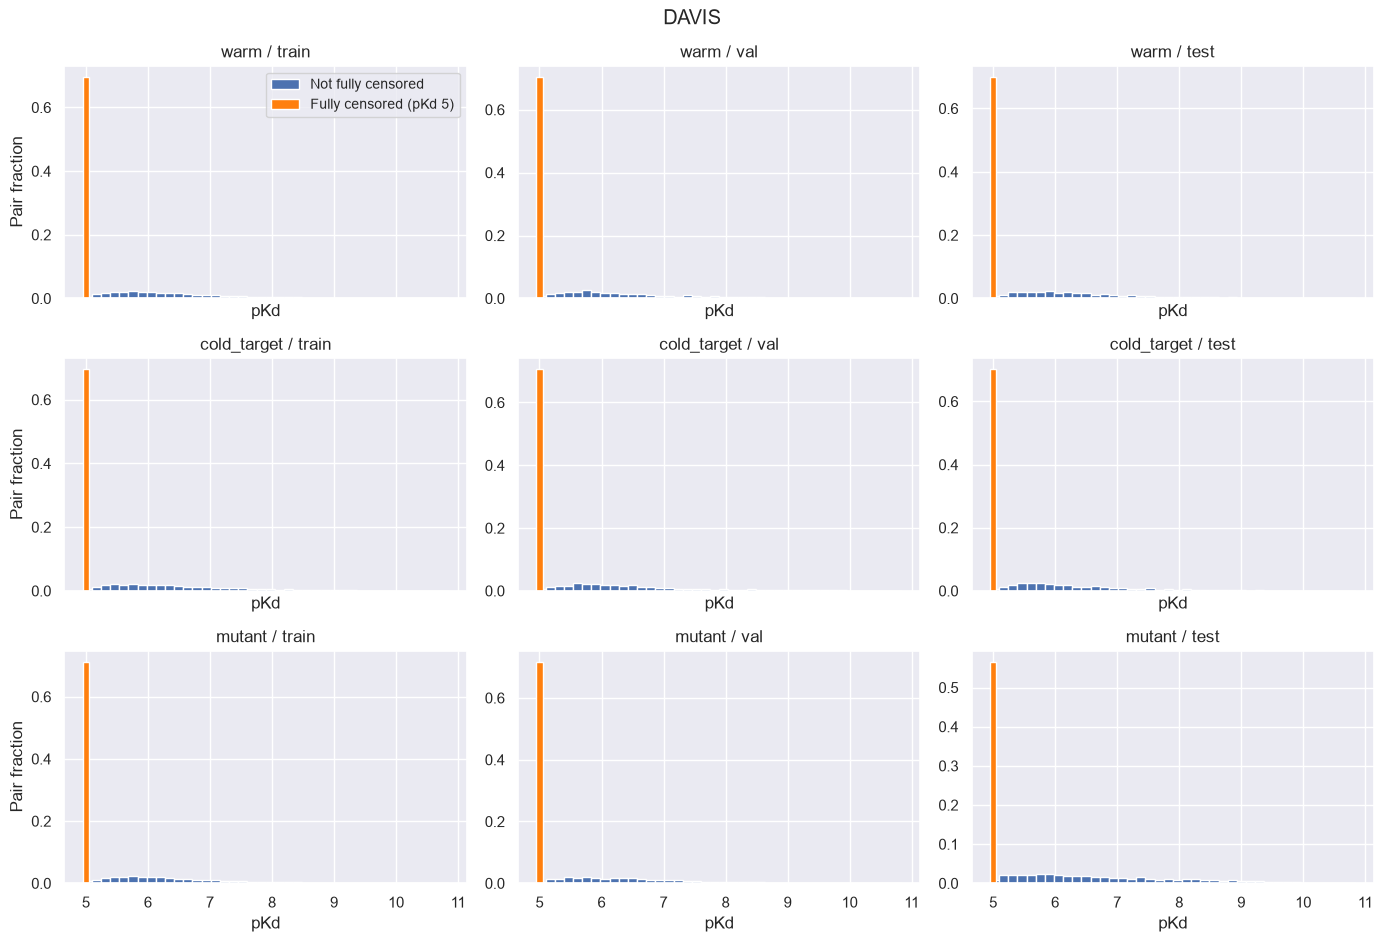

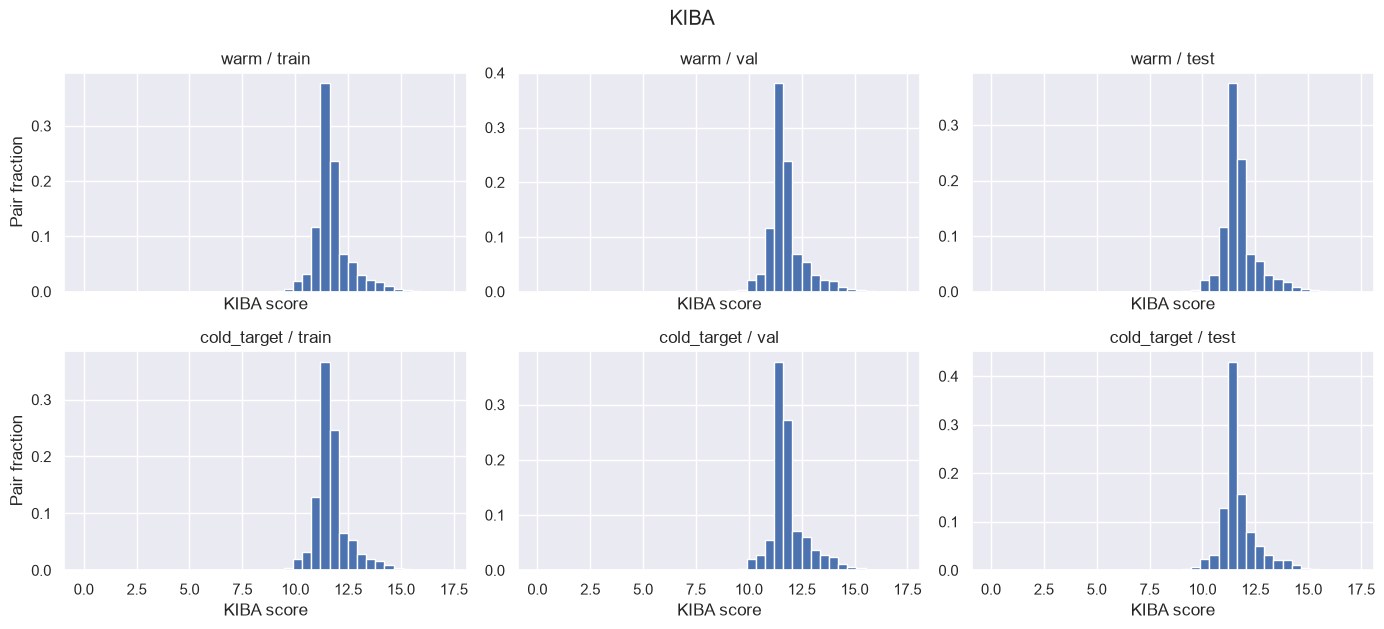

In [7]:
for name, df in pairs.items():
    split_columns = [column for column in df if column.startswith("split_")]
    fig, axes = plt.subplots(len(split_columns), 3, figsize=(14, 3.2 * len(split_columns)),
                             sharex=True, sharey=False, squeeze=False)
    bins = np.linspace(df.score.min() - 0.05, df.score.max() + 0.05, 41)
    for row, split in enumerate(split_columns):
        for col, partition in enumerate(PARTITIONS):
            ax = axes[row, col]
            subset = df[df[split] == partition]
            if name == "davis":
                ax.hist(subset.loc[~subset.censored, "score"], bins=bins,
                        weights=np.full((~subset.censored).sum(), 1 / len(subset)),
                        label="Not fully censored")
                ax.bar(5, subset.censored.sum() / len(subset), width=(bins[1] - bins[0]) * 0.7,
                       color="tab:orange", label="Fully censored (pKd 5)")
                if row == 0 and col == 0:
                    ax.legend(fontsize="small")
            else:
                ax.hist(subset.score, bins=bins, weights=np.full(len(subset), 1 / len(subset)))
            ax.set_title(f"{split.removeprefix('split_')} / {partition}")
            ax.set_xlabel("pKd" if name == "davis" else "KIBA score")
            if col == 0:
                ax.set_ylabel("Pair fraction")
    fig.suptitle(name.upper())
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}_split_scores.png", dpi=150)
    plt.show()
    plt.close(fig)

## 7. Export and reload checks

Gzip timestamps are fixed to zero; NumPy NPZ archives use fixed ZIP timestamps.
All table ordering comes from source insertion order and seeded splits.
Reload checks cover every file, entity references, token row alignment, labels
and split membership. Consumers should join by IDs and use entity CSV row
positions to index the corresponding token arrays.

In [8]:
def export(name):
    """Write and reload one dataset's entities, pairs and token arrays.

    Args:
        name: Dataset key in the inline pipeline's tables.

    Returns:
        None. Writes four processed files and verifies their contents.

    Raises:
        AssertionError: If any round trip changes values or violates references.
    """
    tables = {"ligands": ligands[name], "targets": targets[name], "pairs": pairs[name]}
    reloaded = {}
    for kind, df in tables.items():
        path = PROCESSED / f"{name}_{kind}.csv.gz"
        df.to_csv(path, index=False, compression=GZIP)
        back = pd.read_csv(path, keep_default_na=False,
                           dtype={"ligand_id": str, "target_id": str, "wild_type_id": str,
                                  "merged_ids": str})
        assert len(back) == len(df)
        pd.testing.assert_frame_equal(back, df, check_dtype=False, check_exact=False,
                                      rtol=1e-12, atol=1e-12)
        reloaded[kind] = back
    back = reloaded["pairs"]
    assert np.allclose(back.score, pairs[name].score)
    assert set(back.ligand_id) <= set(reloaded["ligands"].ligand_id)
    assert set(back.target_id) <= set(reloaded["targets"].target_id)
    for column in [column for column in back if column.startswith("split_")]:
        assert set(back[column]) == set(PARTITIONS)
    np.savez_compressed(PROCESSED / f"{name}_tokens.npz", **tokens[name])
    with np.load(PROCESSED / f"{name}_tokens.npz", allow_pickle=False) as arrays:
        assert set(arrays.files) == {"drug_tokens", "prot_tokens"}
        for key, kind, content, modality in (
            ("drug_tokens", "ligands", "smiles", "smiles"),
            ("prot_tokens", "targets", "sequence", "protein"),
        ):
            array = arrays[key]
            assert array.dtype == np.int16
            assert array.shape == (len(reloaded[kind]), MAX_LEN[name][modality])
            assert np.array_equal(array, tokens[name][key])
            for i, string in enumerate(reloaded[kind][content]):
                decoded = "".join(vocab[modality][token - 1] for token in array[i] if token)
                assert decoded == string[:MAX_LEN[name][modality]]


for name in datasets:
    export(name)
(PROCESSED / "vocab.json").write_text(json.dumps(vocab, indent=2) + "\n", encoding="utf-8")
assert json.loads((PROCESSED / "vocab.json").read_text(encoding="utf-8")) == vocab
mutants_back = pd.read_csv(PROCESSED / "davis_mutants.csv", keep_default_na=False)
assert len(mutants_back) == len(mutants)
pd.testing.assert_frame_equal(mutants_back, mutants)
expected_files = {"vocab.json", "davis_mutants.csv"} | {
    f"{name}_{suffix}" for name in datasets
    for suffix in ("ligands.csv.gz", "targets.csv.gz", "pairs.csv.gz", "tokens.npz")
}
assert expected_files <= {path.name for path in PROCESSED.iterdir()}
print("Reload verified for every exported file")
display(pd.DataFrame([
    {"file": filename, "bytes": (PROCESSED / filename).stat().st_size}
    for filename in sorted(expected_files)
]))

Reload verified for every exported file


,file,bytes
0,davis_ligands.csv.gz,1977
1,davis_mutants.csv,6539
2,davis_pairs.csv.gz,175874
3,davis_targets.csv.gz,159191
4,davis_tokens.npz,183506
5,kiba_ligands.csv.gz,36831
6,kiba_pairs.csv.gz,626674
7,kiba_targets.csv.gz,96457
8,kiba_tokens.npz,137516
9,vocab.json,703


## What later phases read

- `{ds}_ligands.csv.gz`: `ligand_id, smiles, merged_ids, n_ids`; rows index `drug_tokens`.
- `{ds}_targets.csv.gz`: `target_id, sequence, merged_ids, n_ids, target_group, is_mutant, wild_type_id, mutation_tag`; rows index `prot_tokens`; KIBA mutant fields are false/empty.
- `{ds}_pairs.csv.gz`: `ligand_id, target_id, score, censored, n_merged, spread, n_censored, split_warm, split_cold_target`, plus DAVIS-only `split_mutant`.
- `{ds}_tokens.npz`: `drug_tokens, prot_tokens`, padded int16 arrays in entity CSV order.
- `vocab.json`: `smiles, protein` character lists (ID = index + 1; padding = 0), and dataset-specific `max_len`.
- `davis_mutants.csv`: `target_id, base, tag, phospho, kind, offset, constructible, reason, wild_type_id, n_edits, seq_len_before, seq_len_after`; construction audit for the mutant stress test.

Here `{ds}` is `davis` or `kiba`. The CNN and DANN phases select a split column
and consume the corresponding labels and token rows. The stress test uses
DAVIS `split_mutant`; unsupported variants are retained as shipped content,
not labelled as constructed mutants. Censor flags and within-group spread
remain available for evaluation and sensitivity analyses.